# Setup
run once at the start

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import torch
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt

from models.autoencoder import AutoEncoder
from scripts.engine import train_model
from datasets.deer_dataset import DeerDataset

In [ ]:
def run_model(size,
              loss_fn,
              optimization,
              lr=1e-3,
              epochs=3):
        model = AutoEncoder()
        train_dataset = DeerDataset("../data/deer-iyhon", split="train")
        train_dataloader = DataLoader(train_dataset,
                                batch_size=32,
                                shuffle=True)
        optimizer = optimization(model.parameters(), lr=lr)
        model, history = train_model(model=model,
                dataloader=train_dataloader,
                optimizer=optimizer,
                loss_fn=loss_fn,
                epochs=3
                )

        plt.plot(history)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.show()

        return model

    

In [2]:
model = AutoEncoder()

In [3]:
train_dataset = DeerDataset("../data/deer-iyhon", split="train")

In [4]:
train_dataloader = DataLoader(train_dataset,
                              batch_size=32,
                              shuffle=True)

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = torch.nn.MSELoss()
model, history = train_model(model=model,
            dataloader=train_dataloader,
            optimizer=optimizer,
            loss_fn=loss_fn,
            epochs=3
            )

Epoch 1/3: 100%|██████████| 96/96 [02:17<00:00,  1.43s/it, loss=0.0147]


Epoch 1 - Loss: 0.0171


Epoch 2/3: 100%|██████████| 96/96 [02:13<00:00,  1.39s/it, loss=0.0089]


Epoch 2 - Loss: 0.0125


Epoch 3/3: 100%|██████████| 96/96 [02:11<00:00,  1.37s/it, loss=0.0109]

Epoch 3 - Loss: 0.0111


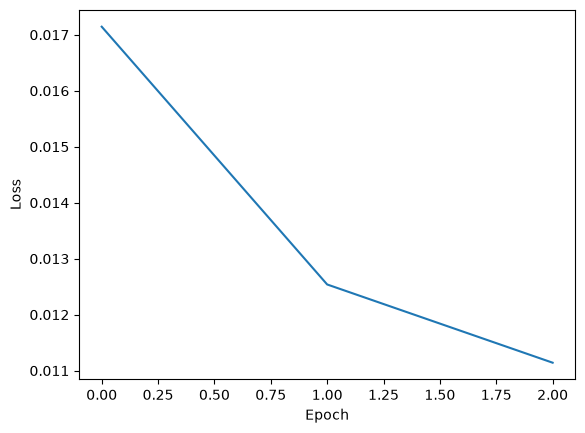

In [7]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [8]:

MODEL_DIR = PROJECT_ROOT / "models" / "pt"

torch.save(
    model.state_dict(),
    MODEL_DIR / "autoencoder.pt")

# Trying 512 px for image

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

from models.autoencoder import AutoEncoder
from scripts.engine import train_model
from datasets.deer_dataset import DeerDataset

In [2]:
model = AutoEncoder(in_size=512)

In [3]:
train_dataset = DeerDataset("../data/deer-iyhon", split="train", image_size=(512, 512))

In [4]:
train_dataloader = DataLoader(train_dataset,
                              batch_size=32,
                              shuffle=True)

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = torch.nn.MSELoss()
model, history = train_model(model=model,
            dataloader=train_dataloader,
            optimizer=optimizer,
            loss_fn=loss_fn,
            epochs=3
            )

Epoch 1/3: 100%|██████████| 96/96 [04:11<00:00,  2.62s/it, loss=0.0356]


Epoch 1 - Loss: 0.0486


Epoch 2/3: 100%|██████████| 96/96 [03:46<00:00,  2.36s/it, loss=0.0140]


Epoch 2 - Loss: 0.0181


Epoch 3/3: 100%|██████████| 96/96 [03:36<00:00,  2.25s/it, loss=0.0179]

Epoch 3 - Loss: 0.0152


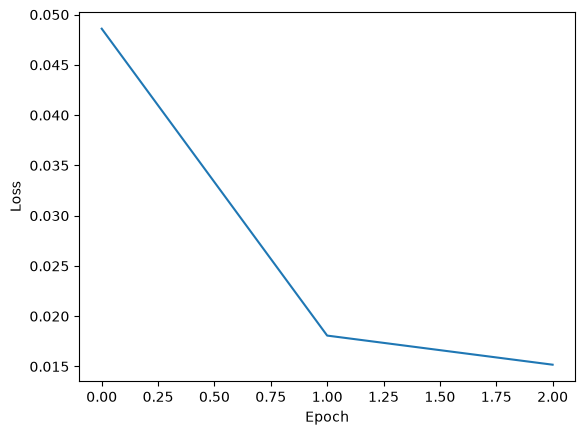

In [6]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [7]:

MODEL_DIR = PROJECT_ROOT / "models" / "pt"

torch.save(
    model.state_dict(),
    MODEL_DIR / "autoencoder512.pt")

# Trying 256 with n1Loss

In [8]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

from models.autoencoder import AutoEncoder
from scripts.engine import train_model
from datasets.deer_dataset import DeerDataset

In [9]:
model = AutoEncoder(in_size=256)

In [10]:
train_dataset = DeerDataset("../data/deer-iyhon", split="train", image_size=(256, 256))

In [11]:
train_dataloader = DataLoader(train_dataset,
                              batch_size=32,
                              shuffle=True)

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = torch.nn.L1Loss()
model, history = train_model(model=model,
            dataloader=train_dataloader,
            optimizer=optimizer,
            loss_fn=loss_fn,
            epochs=3
            )

Epoch 1/3: 100%|██████████| 96/96 [01:39<00:00,  1.04s/it, loss=0.1222]


Epoch 1 - Loss: 0.1778


Epoch 2/3: 100%|██████████| 96/96 [02:00<00:00,  1.25s/it, loss=0.0955]


Epoch 2 - Loss: 0.1022


Epoch 3/3: 100%|██████████| 96/96 [01:34<00:00,  1.01it/s, loss=0.0727]

Epoch 3 - Loss: 0.0886


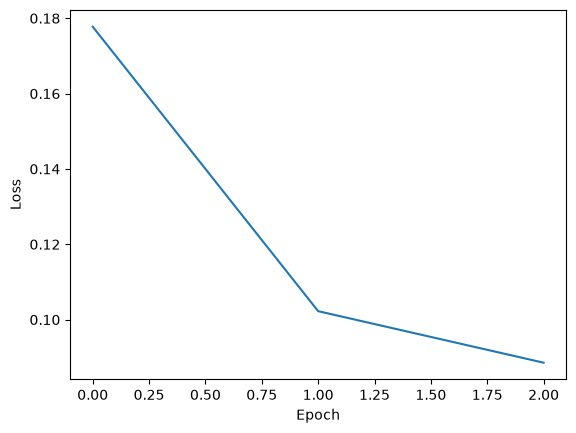

In [13]:
import matplotlib.pyplot as plt

plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [14]:

MODEL_DIR = PROJECT_ROOT / "models" / "pt"

torch.save(
    model.state_dict(),
    MODEL_DIR / "autoencoder256L1.pt")